# Nifty expiry and dealer gamma: a walk through the real data

This notebook is a guided tour of the project on **real NSE data**. It is meant to be read top to bottom, by someone new to options.

1. Load one evening's Nifty option chain from NSE's bhavcopy.
2. Turn prices into implied volatilities and gamma, and build the **gamma exposure (GEX) profile**: how much hedging dealers might have to do for a 1% move, strike by strike.
3. Watch what the index did the next day, which was an expiry day.
4. Look at the whole sample: how GEX moves over time under three guesses about who is on the other side of the trade.
5. Compare the intraday volatility pattern on expiry days and other days.
6. Show the out-of-sample forecasting scoreboard (the project's headline test).

**Data needed:** run the commands in `docs/DATA_ACQUISITION.md` first (all free, about 25 minutes). Sections 4 and 6 read the outputs of `scripts/run_pipeline.py --source nse`, which are committed in `results/pipeline_nse_v2/`. If `data/raw/` is missing, the cells that need it say so and stop.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from niftygex import data, greeks, gex
from niftygex.expiry_calendar import label_days

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
RAW, RES = ROOT / "data" / "raw", ROOT / "results" / "pipeline_nse_v2"
HAVE_RAW = (RAW / "bhavcopy").exists() and (RAW / "nifty_1min.csv").exists()
print("raw data found:", HAVE_RAW, "| pipeline results found:", RES.exists())
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

raw data found: True | pipeline results found: True


## 1. One evening's option chain

NSE publishes a **bhavcopy** after every trading day: one row per option contract with its settlement price and **open interest** (OI, the number of contracts still open). We pick the most recent Nifty expiry in the data and load the chain published the evening before it. That evening's chain is exactly what a trader would have known going into expiry day.

One fact we checked on the real files: OI in the bhavcopy is in **shares** (units of the index), not in contracts. Adding up OI divided by each row's lot size reproduces NSE's participant-wise totals exactly.

In [2]:
assert HAVE_RAW, "Download the data first (docs/DATA_ACQUISITION.md)"
files = data.bhavcopy_files(RAW / "bhavcopy")
recent = {pd.Timestamp(data.load_bhavcopy(f)["date"].iloc[0]).normalize(): data.load_bhavcopy(f) for f in files[-15:]}
expiries = data.actual_expiries(recent)
expiry = expiries[-1]
eve = max(d for d in recent if d < expiry)
chain = recent[eve]
chain = chain[chain["expiry"] == expiry].copy()
print(f"Expiry day: {expiry.date()}  |  chain published on: {eve.date()}  |  {len(chain)} option series")
chain.head()

Expiry day: 2026-10-27  |  chain published on: 2026-10-26  |  288 option series


,date,symbol,expiry,strike,is_call,close,settle,oi,chg_oi,volume,underlying,lot_size
0,2026-10-26,NIFTY,2026-10-27,20050.0,False,0.50,0.50,5391100.0,-1473615.0,204963.0,22753.2,65.0
1,2026-10-26,NIFTY,2026-10-27,20100.0,False,0.50,0.50,4154020.0,-926705.0,200400.0,22753.2,65.0
2,2026-10-26,NIFTY,2026-10-27,20150.0,False,0.70,0.70,177450.0,125450.0,21870.0,22753.2,65.0
3,2026-10-26,NIFTY,2026-10-27,20200.0,False,0.70,0.70,364845.0,-41470.0,46910.0,22753.2,65.0
4,2026-10-26,NIFTY,2026-10-27,20250.0,False,0.75,0.75,118950.0,84695.0,16387.0,22753.2,65.0


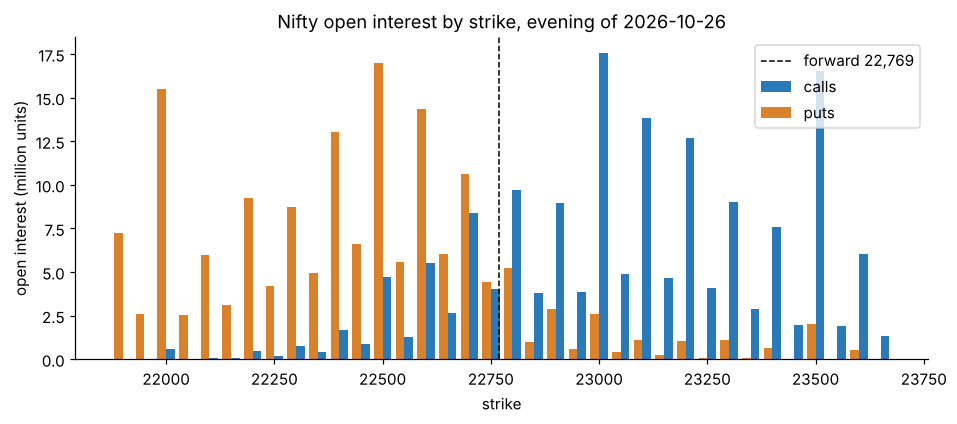

In [3]:
T = 1 / 252                               # one trading day to expiry
r = 0.065
F = data.parity_forward(chain, T, r)      # forward price from put-call parity
calls, puts = chain[chain.is_call], chain[~chain.is_call]
win = (chain.strike > F * 0.96) & (chain.strike < F * 1.04)
fig, ax = plt.subplots(figsize=(10, 3.8))
c, p = calls[win[calls.index]], puts[win[puts.index]]
ax.bar(c.strike + 10, c.oi / 1e6, width=20, label="calls", color="#2a7ab9")
ax.bar(p.strike - 10, p.oi / 1e6, width=20, label="puts", color="#d9822b")
ax.axvline(F, color="k", lw=1, ls="--", label=f"forward {F:,.0f}")
ax.set(xlabel="strike", ylabel="open interest (million units)", title=f"Nifty open interest by strike, evening of {eve.date()}")
ax.legend(); plt.show()

## 2. From prices to gamma exposure

For each option we back out the **implied volatility** from its settlement price (Black-76 model), then its **gamma**: how fast the option's delta changes when the index moves. Multiplying gamma by open interest and by $S^2 \times 1\%$ gives the rupee amount of index that the holders of that option would need to buy or sell to stay hedged after a 1% move. That is the strike's **gamma exposure (GEX)**.

The catch is the sign. If dealers are *long* that gamma, their hedging sells rallies and buys dips (calming the market); if they are *short*, hedging chases the move. Public data do not show who is long. We keep three guesses side by side:

* **US convention**: dealers long calls and short puts (common in US work, possibly wrong for India).
* **Pro participant**: dealers hold the same net share as NSE's "Pro" category in the participant file.
* **Mirror of Client**: dealers take the other side of retail "Client" positions.

Forward 22,768.6 | ATM implied vol (annualised): 16.3%
Net GEX (US sign): 1,349 crore per 1% | gamma flip 22,763 | call wall 23,000 | put wall 22,500 | max pain 22,750


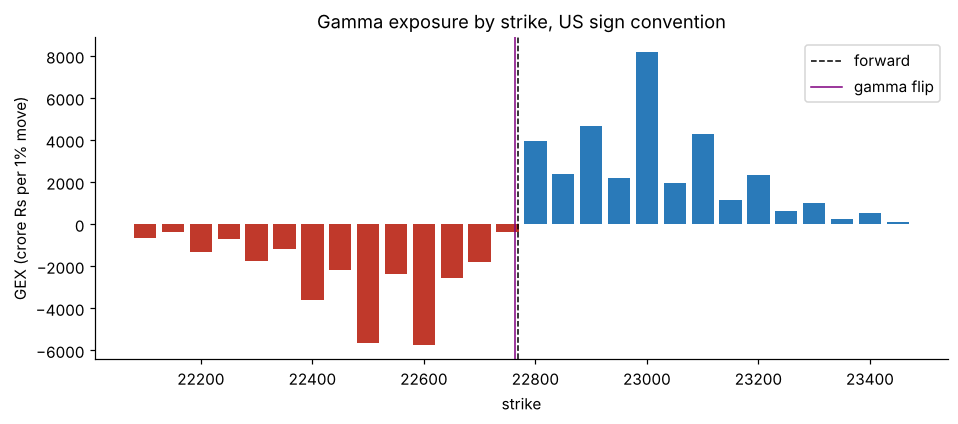

In [4]:
iv = greeks.implied_vol(chain["settle"].to_numpy(), F, chain["strike"].to_numpy(), T, r, chain["is_call"].to_numpy())
chain["iv"] = pd.Series(iv, index=chain.index).groupby(chain["is_call"]).transform(lambda s: s.interpolate(limit_direction="both"))
ch = chain[chain.oi > 0]
tab = gex.strike_gex(ch, F, 1.0, T, r, 0.0, "us_convention")   # lot size 1 because OI is already in shares
by_k = tab.groupby("strike")["gex"].sum() / 1e7                # crore rupees per 1% move
flip = gex.gamma_flip(ch, F, 1.0, T, r, 0.0, "us_convention")
walls = gex.oi_walls(ch); mp = gex.max_pain(ch)
cs = chain[chain.is_call].sort_values("strike")
print(f"Forward {F:,.1f} | ATM implied vol (annualised): {np.interp(F, cs.strike, cs.iv):.1%}")
print(f"Net GEX (US sign): {by_k.sum():,.0f} crore per 1% | gamma flip {flip:,.0f} | call wall {walls['call_wall']:,.0f} | put wall {walls['put_wall']:,.0f} | max pain {mp:,.0f}")
kk = by_k[(by_k.index > F * 0.97) & (by_k.index < F * 1.03)]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(kk.index, kk.values, width=40, color=np.where(kk.values >= 0, "#2a7ab9", "#c0392b"))
ax.axvline(F, color="k", lw=1, ls="--", label="forward")
if np.isfinite(flip): ax.axvline(flip, color="purple", lw=1, label="gamma flip")
ax.set(xlabel="strike", ylabel="GEX (crore Rs per 1% move)", title="Gamma exposure by strike, US sign convention")
ax.legend(); plt.show()

## 3. What happened on expiry day

Here is the index minute by minute on the expiry day itself, with the strikes that the evening-before chain flagged. The **pinning** idea says that heavy hedging around a big strike can pull the close toward it on expiry. One day proves nothing either way; the dedicated pinning study tests it over all 200 expiries.

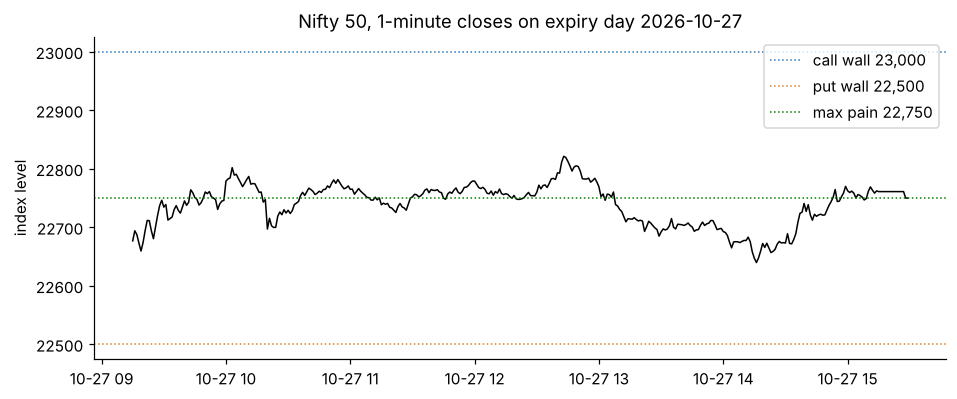

In [5]:
bars = data.load_minute_bars(RAW / "nifty_1min.csv")
day = bars[bars.index.normalize() == expiry]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(day.index, day["close"], color="k", lw=1)
for lvl, name, col in ((walls["call_wall"], "call wall", "#2a7ab9"), (walls["put_wall"], "put wall", "#d9822b"), (mp, "max pain", "green")):
    ax.axhline(lvl, color=col, lw=1, ls=":", label=f"{name} {lvl:,.0f}")
ax.set(title=f"Nifty 50, 1-minute closes on expiry day {expiry.date()}", ylabel="index level")
ax.legend(loc="best"); plt.show()

## 4. GEX over the whole sample

The pipeline computes the same numbers for every evening from January 2023 to November 2026. Dividing by the 20-day median of gross GEX makes days comparable. Notice that the Pro-participant version drifts from negative to positive over the sample: any test that uses it must allow for slow changes in the market (we control for the expiry regime).

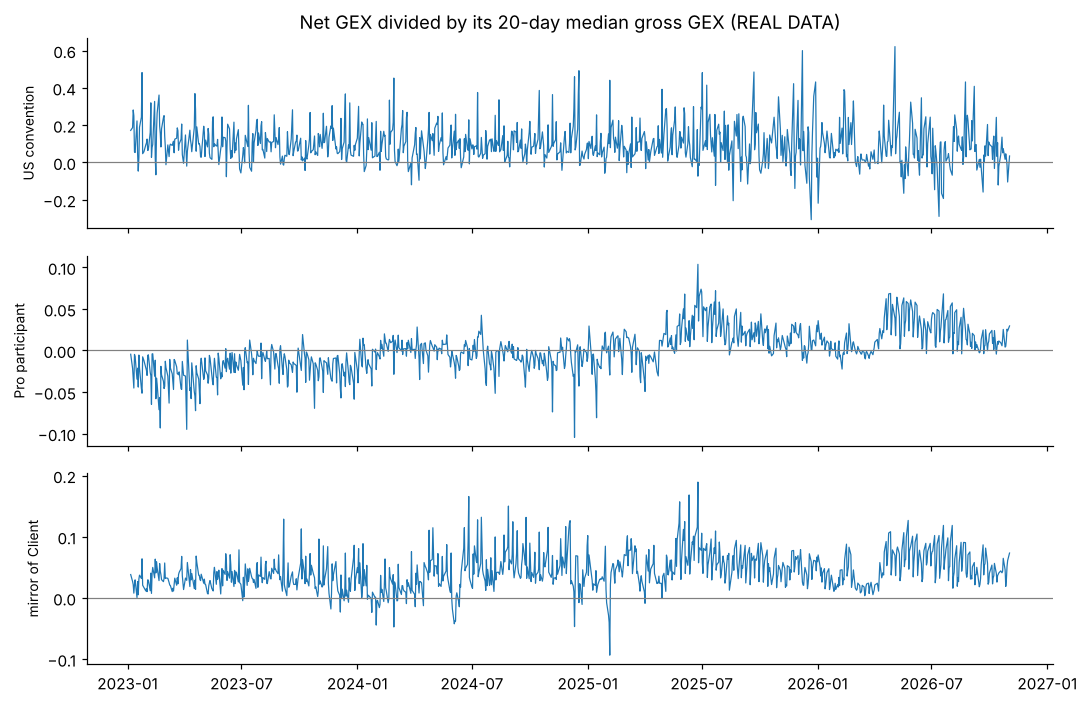

In [6]:
panel = pd.read_csv(RES / "daily_gex_panel.csv", index_col=0, parse_dates=True)
scale = panel["gross_gex"].rolling(20, min_periods=5).median()
fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
for ax, (col, name) in zip(axes, [("net_gex_us_convention", "US convention"), ("net_gex_participant", "Pro participant"), ("net_gex_client_mirror", "mirror of Client")]):
    ax.plot(panel.index, panel[col] / scale, lw=0.8); ax.axhline(0, color="grey", lw=0.8); ax.set_ylabel(name, fontsize=9)
axes[0].set_title("Net GEX divided by its 20-day median gross GEX (REAL DATA)")
plt.tight_layout(); plt.show()

## 5. The intraday shape of volatility

Volatility is not spread evenly over the day: it is high at the open, quiet at lunch and rises into the close. The paper's mcsGARCH model has a separate "diurnal" curve for this. Below: average squared 1-minute return by time of day, on expiry days and on other days, for each expiry regime.

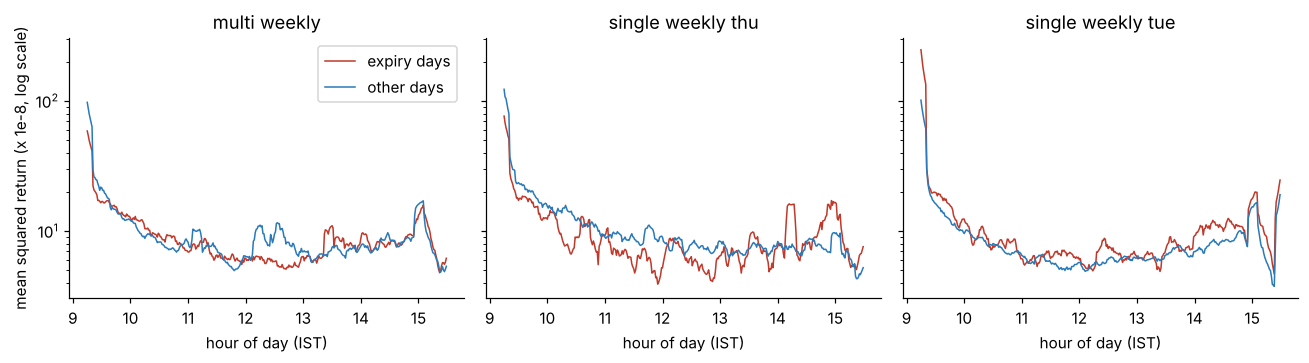

In [7]:
dm = pd.read_csv(RES / "daily_market.csv", index_col=0, parse_dates=True)
grid = data.to_session_grid(bars[(bars.index >= dm.index.min()) & (bars.index < dm.index.max() + pd.Timedelta(days=1))])
R2 = pd.DataFrame(grid["returns"] ** 2, index=grid["days"]).reindex(dm.index)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, reg in zip(axes, ["multi_weekly", "single_weekly_thu", "single_weekly_tue"]):
    m = dm["regime"] == reg
    for flag, col, lab in ((True, "#c0392b", "expiry days"), (False, "#2a7ab9", "other days")):
        sel = R2[m & (dm["is_expiry"] == flag)]
        ax.plot(np.arange(375) / 60 + 9.25, sel.mean().rolling(10, center=True, min_periods=1).mean() * 1e8, color=col, lw=1, label=lab)
    ax.set(title=reg.replace("_", " "), xlabel="hour of day (IST)", yscale="log")
axes[0].set_ylabel("mean squared return (x 1e-8, log scale)"); axes[0].legend(); plt.tight_layout(); plt.show()

## 6. The headline test: who forecasts volatility best?

Every model forecasts the realized variance of the next 15 or 30 minutes, or of the last hour, and is refitted every 21 trading days using only past data. The bars show how much lower (better) each model's QLIKE loss is than the paper's mcsGARCH. The **GEX ablation** compares the same model with and without the gamma features.

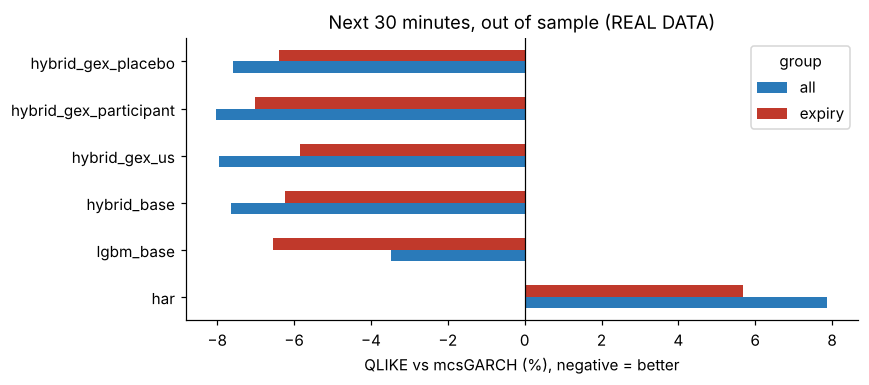

,group,label,days,change_pct,p_one_sided,p_holm_in_family
9,all,gross,792,-0.4163,0.0236,0.0943
10,all,us,792,-0.3330,0.1010,0.2020
11,all,participant,792,-0.4075,0.0452,0.1355
12,all,client,792,-0.3224,0.1367,0.2020
13,all,placebo,792,0.0767,0.6122,NaN
41,expiry,gross,169,-0.3582,0.1912,0.5735
42,expiry,us,169,0.4020,0.8012,0.8012
43,expiry,participant,169,-0.8407,0.0720,0.2880
44,expiry,client,169,-0.2111,0.3207,0.6415
45,expiry,placebo,169,-0.1743,0.2966,NaN


In [8]:
sb = pd.read_csv(RES / "scoreboard_next30.csv")
show = ["har", "lgbm_base", "hybrid_base", "hybrid_gex_us", "hybrid_gex_participant", "hybrid_gex_placebo"]
pv = sb[sb.model.isin(show)].pivot(index="model", columns="group", values="qlike_vs_mcsgarch_pct").loc[show]
ax = pv[["all", "expiry"]].plot.barh(figsize=(8, 3.6), color=["#2a7ab9", "#c0392b"])
ax.axvline(0, color="k", lw=0.8); ax.set(xlabel="QLIKE vs mcsGARCH (%), negative = better", ylabel="", title="Next 30 minutes, out of sample (REAL DATA)")
plt.tight_layout(); plt.show()
# GEX ablation: the same hybrid with and without a block of GEX features (change in QLIKE, %; negative = GEX helps)
abl = pd.read_csv(RES / "ablation_next30.csv")
abl[abl.family.str.startswith("hybrid: base vs base+GEX") & abl.group.isin(["all", "expiry"])][
    ["group", "label", "days", "change_pct", "p_one_sided", "p_holm_in_family"]].round(4)

## What to take away

* Correcting the paper's mcsGARCH with a machine-learning model of its errors improves short-horizon forecasts (about 6% and 8% lower QLIKE at 15 and 30 minutes over 792 test days), and the improvement is statistically clear. Part of it is extra information (India VIX and option prices): against an mcsGARCH given the same information the gain is about 5% and 6% (`docs/REFEREE_RESPONSE_FORECAST.md`).
* End-of-day gamma exposure does not improve those forecasts under any of the three sign guesses (the placebo row is GEX from a random earlier day).
* The one in-sample GEX pattern that survived hard testing is an end-of-day reversal after evenings when the "Pro" participants were net short options; it is about Pro positioning rather than gamma (`docs/FALSIFICATION.md`, `docs/REFEREE_RESPONSE_F2.md`).

All numbers here come from real NSE data; the simulation studies that motivated the tests are in `docs/EXPERIMENT_REPORT.md`.